# Example of the AiTLAS toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import UDD6Dataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import ResizeToTensor

## Visualize images and masks

Total number of patches: 141


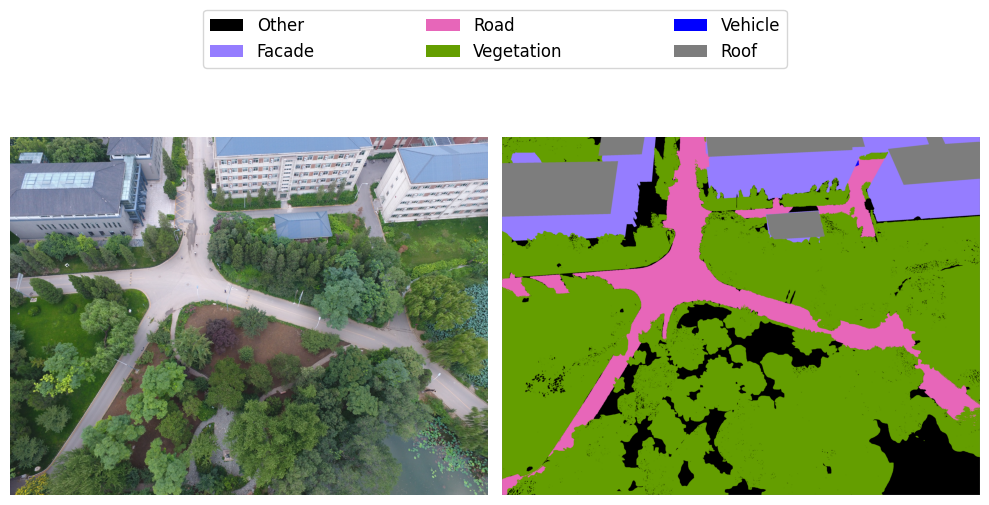

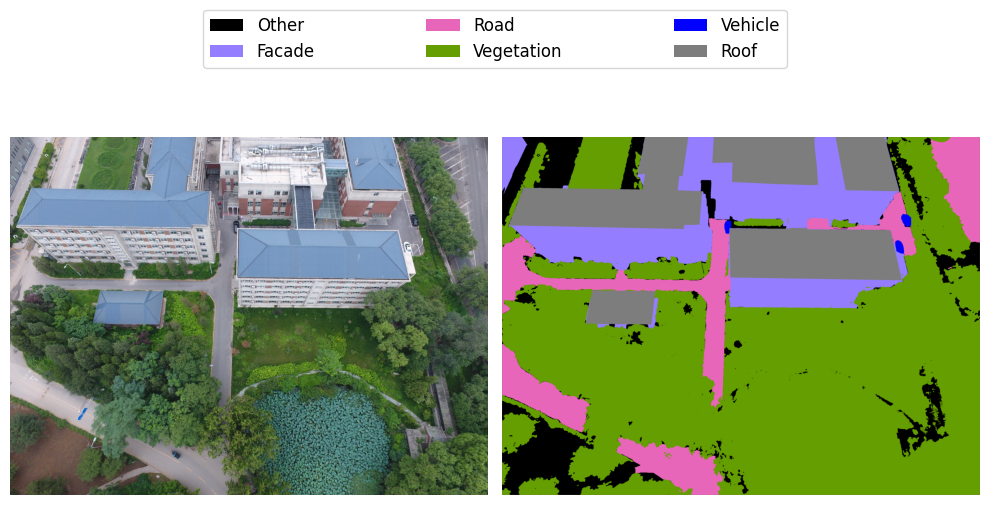

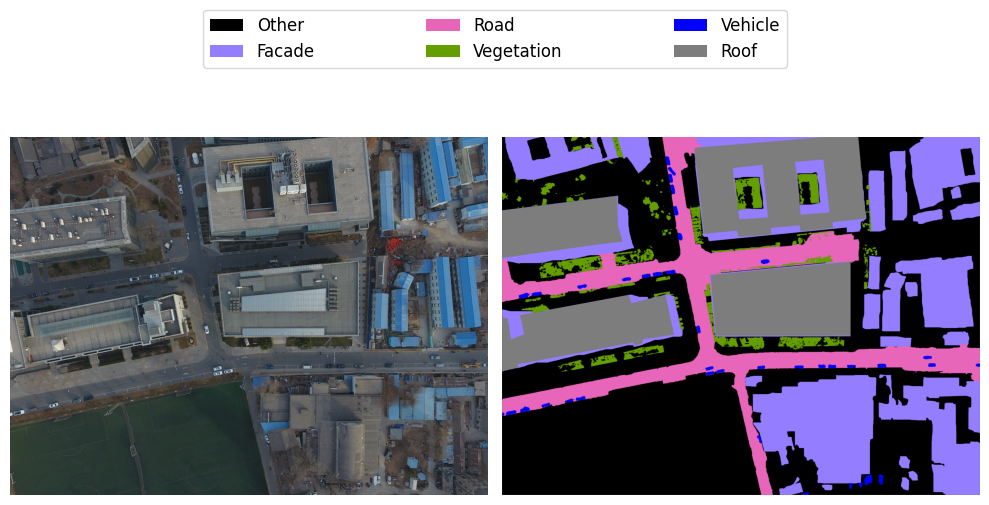

In [ ]:
dataset_config = {
    "data_dir": "./data/UDD6"
}
dataset = UDD6Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(15);
dataset.show_image(112);

In [7]:
dataset.data_distribution_table()

,Number of pixels
Other,281161651.0
Facade,235298602.0
Road,199846636.0
Vegetation,419270794.0
Vehicle,13882349.0
Roof,382365888.0


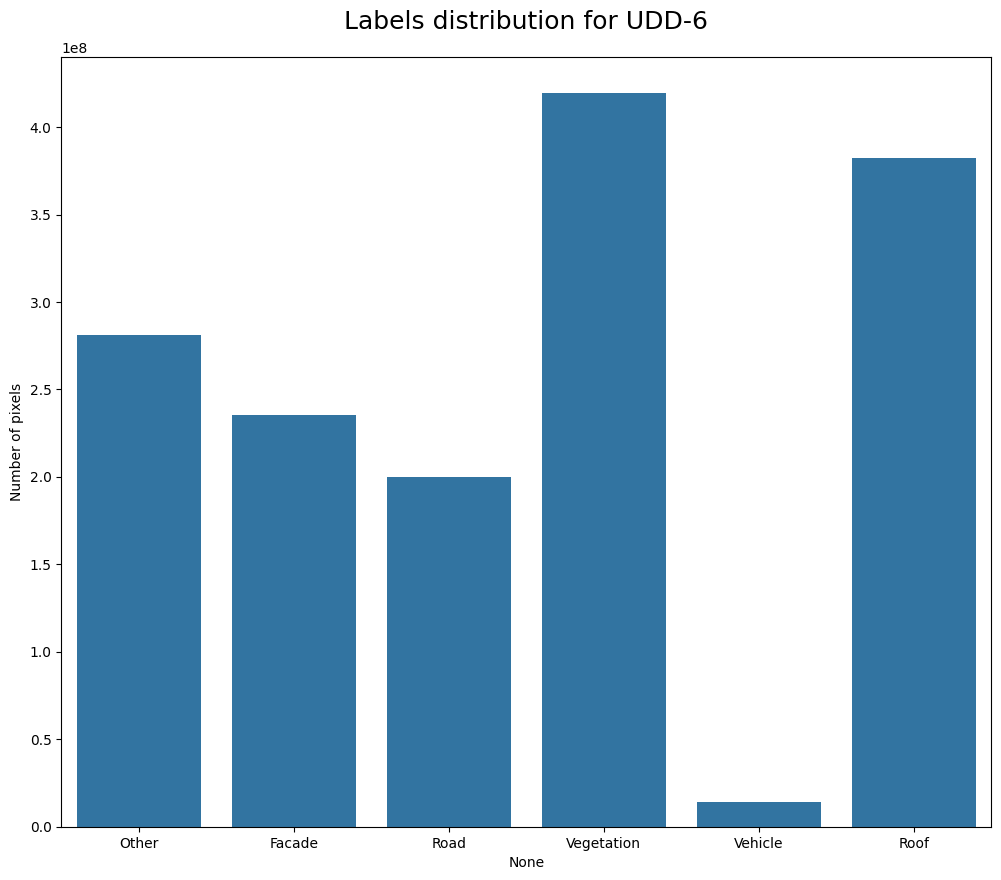

In [8]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 2,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/UDD6/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = UDD6Dataset(train_dataset_config)
len(train_dataset)

106

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/UDD6"
model_config = {
    "num_classes": 6, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [12]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-02-26 13:44:22,022 INFO Starting training.
training: 100%|██████████| 53/53 [00:21<00:00,  2.51it/s]
2025-02-26 13:44:43,211 INFO epoch: 1, time: 21, loss:  0.71356
testing on train set: 100%|██████████| 53/53 [00:20<00:00,  2.63it/s]
2025-02-26 13:45:04,945 INFO IOU:0.26348102994893713, IOU mean:0.2672958311809517, IOU per Class:[0.20826707 0.28691504 0.18844641 0.47663261 0.00776319 0.43575066]
training: 100%|██████████| 53/53 [00:19<00:00,  2.68it/s]
2025-02-26 13:45:24,737 INFO epoch: 2, time: 20, loss:  0.62991
testing on train set: 100%|██████████| 53/53 [00:20<00:00,  2.56it/s]
2025-02-26 13:45:45,478 INFO IOU:0.3801098076493464, IOU mean:0.3444816050135959, IOU per Class:[0.29146743 0.29073961 0.29326463 0.56576286 0.02427065 0.60138446]
training: 100%|██████████| 53/53 [00:20<00:00,  2.60it/s]
2025-02-26 13:46:05,831 INFO epoch: 3, time: 20, loss:  0.57773
testing on train set: 100%|██████████| 53/53 [00:20<00:00,  2.62it/s]
2025-02-26 13:46:26,099 INFO IOU:0.496909080735

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/UDD6/val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = UDD6Dataset(test_dataset_config)
len(test_dataset)

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/UDD6/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-02-26 13:51:13,957 INFO Loading checkpoint /home/dragik/data/FAIR_EO/UDD6/checkpoint.pth.tar
2025-02-26 13:51:14,360 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/UDD6/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 9/9 [00:06<00:00,  1.38it/s]


[{'IOU': 0.6084394333692026,
  'IOU mean': 0.48823983356266715,
  'IOU per Class': array([0.47505984, 0.53307843, 0.51128504, 0.65876724, 0.        ,
         0.75124846])}]

## Predictions

2025-03-10 09:47:42,920 INFO Loading checkpoint /home/dragik/data/FAIR_EO/UDD6/checkpoint.pth.tar
2025-03-10 09:47:43,424 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/UDD6/checkpoint.pth.tar at epoch 11


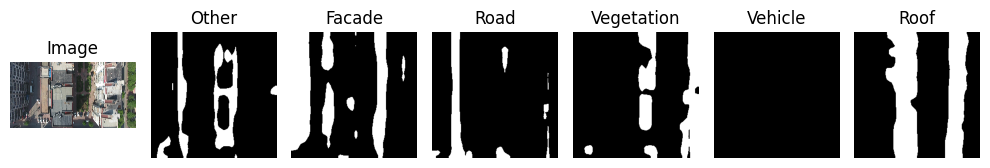

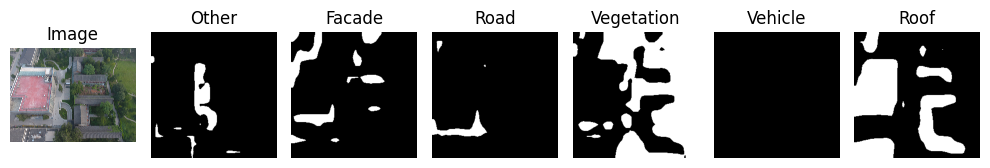

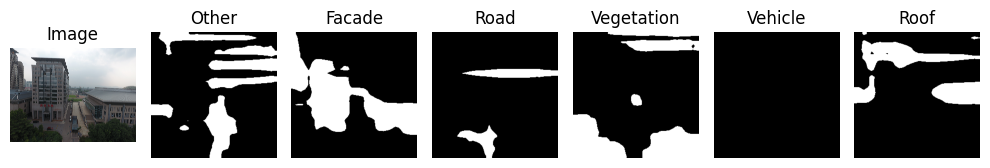

In [ ]:
model_path = "./data/UDD6/checkpoint.pth.tar"
labels = ["Other","Facade","Road","Vegetation","Vehicle","Roof"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('./data/UDD6/val/src/000361.JPG')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/UDD6/val/src/DJI_0291.JPG')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/UDD6/val/src/DJI_00528.JPG')
fig = model.predict_masks(image, labels, transform)